# IMERG HDF5 -> filtered hourly 0.1° precipitation (any year)
This notebook takes PPS precipitation data and makes it into a parquet file. 
It also works to filter precipitation data for quality as well as space. It does not use shapefiles, and it does not filter out urban areas. Rather, it just looks at entire midwest region as a whole.

It filters for:
- precipitation quality index
- probability liquid precipitation

It also works to:
- implement grid size
- converts half hourly to hourly

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
from tqdm import tqdm

In [2]:
YEAR = 2024
IMERG_DIR = Path(f"/global/scratch/users/rubypercival/IMERG{str(YEAR)[-2:]}")  
OUT_DIR = IMERG_DIR / "parquet" / "filtered_FIXED"
OUT_FILE = OUT_DIR / f"IMERG_CONUS_0.1x0.1_hourly_filtered_{YEAR}_FIXED.parquet"

LAT_MIN, LAT_MAX = 36.0, 49.0     
LON_MIN, LON_MAX = -104.0, -80.0  
QUALITY_THRESHOLD = 0.6          
PROB_THRESHOLD = 90               
MONTHS = [3, 4, 5, 6, 7]

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("input :", IMERG_DIR)
print("output:", OUT_FILE)

input : /global/scratch/users/rubypercival/IMERG24
output: /global/scratch/users/rubypercival/IMERG24/parquet/filtered_FIXED/IMERG_CONUS_0.1x0.1_hourly_filtered_2024_FIXED.parquet


In [3]:
files = sorted(p for p in IMERG_DIR.rglob("*") if p.is_file() and p.suffix.lower() in {".hdf5", ".h5"})
pat = re.compile(r"\.(\d{8})-S(\d{6})-")

def start_time(p):
    m = pat.search(p.name)
    return pd.to_datetime(m.group(1) + m.group(2), format="%Y%m%d%H%M%S") if m else pd.NaT

ftab = pd.DataFrame({"path": files, "start": [start_time(p) for p in files]}).dropna()
ftab = ftab[ftab["start"].dt.year.eq(YEAR) & ftab["start"].dt.month.isin(MONTHS)].sort_values("start").reset_index(drop=True)

expected = pd.date_range(f"{YEAR}-{MONTHS[0]:02d}-01", f"{YEAR}-{MONTHS[-1] + 1:02d}-01", freq="30min", inclusive="left")
missing = expected.difference(ftab["start"])
print(f"{len(ftab):,} half-hourly files found, {len(expected):,} expected, {len(missing):,} missing")
if len(missing):
    print("missing half-hours per month:", pd.Series(missing.month).value_counts().sort_index().to_dict())

7,344 half-hourly files found, 7,344 expected, 0 missing


In [4]:
with h5py.File(ftab["path"].iloc[0], "r") as f:
    g = f["Grid"]
    lat_all, lon_all = g["lat"][:], g["lon"][:]
    shp = g["precipitation"].shape
assert shp == (1, len(lon_all), len(lat_all)), f"unexpected layout {shp} -- stop and check"
print("layout OK: precipitation is (time, lon, lat) =", shp)

ilat = np.where((lat_all >= LAT_MIN) & (lat_all <= LAT_MAX))[0]
ilon = np.where((lon_all >= LON_MIN) & (lon_all <= LON_MAX))[0]
lat_sl, lon_sl = slice(ilat[0], ilat[-1] + 1), slice(ilon[0], ilon[-1] + 1)
lats, lons = np.round(lat_all[lat_sl].astype(float), 2), np.round(lon_all[lon_sl].astype(float), 2)
print(f"domain: {len(lats)} lats ({lats[0]}..{lats[-1]}) x {len(lons)} lons ({lons[0]}..{lons[-1]})")
LAT2, LON2 = np.meshgrid(lats, lons, indexing="ij")   # (lat, lon) -- matches the transposed arrays below

layout OK: precipitation is (time, lon, lat) = (1, 3600, 1800)
domain: 130 lats (36.05..48.95) x 240 lons (-103.95..-80.05)


## Read, quality-filter, and aggregate to hourly

In [5]:
def read_halfhour(path):
    """precipitation rate (mm/hr) on the domain as (lat, lon); NaN where invalid or failing QC."""
    with h5py.File(path, "r") as f:
        g = f["Grid"]
        p = g["precipitation"][0, lon_sl, lat_sl].T.astype("float32")          # (lon, lat) -> (lat, lon)
        q = g["precipitationQualityIndex"][0, lon_sl, lat_sl].T
        pl = g["probabilityLiquidPrecipitation"][0, lon_sl, lat_sl].T
    ok = (p >= 0) & (q > QUALITY_THRESHOLD) & (pl > PROB_THRESHOLD)
    return np.where(ok, p, np.nan)

ftab["hour"] = ftab["start"].dt.floor("h")
monthly_files = []
for month in MONTHS:
    hours = ftab[ftab["hour"].dt.month == month].groupby("hour")["path"].apply(list)
    frames = []
    for hour, paths in tqdm(hours.items(), total=len(hours), desc=f"{YEAR}-{month:02d}"):
        stack = np.stack([read_halfhour(p) for p in paths])          # (n_halfhours, lat, lon)
        n_valid = np.isfinite(stack).sum(axis=0)
        with np.errstate(invalid="ignore"):
            mean_rate = np.nanmean(stack, axis=0) if len(paths) > 1 else stack[0]
        frames.append(pd.DataFrame({"grid_lat": LAT2.ravel(), "grid_lon": LON2.ravel(), "hour": hour,
                                    "h_precip_mm": (mean_rate * 1.0).ravel().astype("float32"),   # mm/hr x 1 h = mm
                                    "n_halfhours": n_valid.ravel().astype("int8")}))
    out = OUT_DIR / f"month_{month:02d}.parquet"
    pd.concat(frames, ignore_index=True).to_parquet(out, engine="pyarrow", index=False)
    monthly_files.append(out)
    print(f"  saved {out}")

2024-03:   0%|          | 0/744 [00:00<?, ?it/s]/tmp/ipykernel_2312193/98543167.py:20: RuntimeWarning: Mean of empty slice
  mean_rate = np.nanmean(stack, axis=0) if len(paths) > 1 else stack[0]
2024-03: 100%|██████████| 744/744 [01:26<00:00,  8.62it/s]


  saved /global/scratch/users/rubypercival/IMERG24/parquet/filtered_FIXED/month_03.parquet


2024-04:   0%|          | 0/720 [00:00<?, ?it/s]/tmp/ipykernel_2312193/98543167.py:20: RuntimeWarning: Mean of empty slice
  mean_rate = np.nanmean(stack, axis=0) if len(paths) > 1 else stack[0]
2024-04: 100%|██████████| 720/720 [01:21<00:00,  8.79it/s]


  saved /global/scratch/users/rubypercival/IMERG24/parquet/filtered_FIXED/month_04.parquet


2024-05:   0%|          | 0/744 [00:00<?, ?it/s]/tmp/ipykernel_2312193/98543167.py:20: RuntimeWarning: Mean of empty slice
  mean_rate = np.nanmean(stack, axis=0) if len(paths) > 1 else stack[0]
2024-05: 100%|██████████| 744/744 [01:30<00:00,  8.22it/s]


  saved /global/scratch/users/rubypercival/IMERG24/parquet/filtered_FIXED/month_05.parquet


2024-06:   0%|          | 0/720 [00:00<?, ?it/s]/tmp/ipykernel_2312193/98543167.py:20: RuntimeWarning: Mean of empty slice
  mean_rate = np.nanmean(stack, axis=0) if len(paths) > 1 else stack[0]
2024-06: 100%|██████████| 720/720 [01:23<00:00,  8.60it/s]


  saved /global/scratch/users/rubypercival/IMERG24/parquet/filtered_FIXED/month_06.parquet


2024-07:   0%|          | 0/744 [00:00<?, ?it/s]/tmp/ipykernel_2312193/98543167.py:20: RuntimeWarning: Mean of empty slice
  mean_rate = np.nanmean(stack, axis=0) if len(paths) > 1 else stack[0]
2024-07: 100%|██████████| 744/744 [01:27<00:00,  8.54it/s]


  saved /global/scratch/users/rubypercival/IMERG24/parquet/filtered_FIXED/month_07.parquet


In [6]:
hourly = pd.concat([pd.read_parquet(p) for p in monthly_files], ignore_index=True)
hourly.to_parquet(OUT_FILE, engine="pyarrow", index=False)
print("Saved:", OUT_FILE, hourly.shape)

Saved: /global/scratch/users/rubypercival/IMERG24/parquet/filtered_FIXED/IMERG_CONUS_0.1x0.1_hourly_filtered_2024_FIXED.parquet (114566400, 5)


In [7]:
v = hourly.dropna(subset=["h_precip_mm"])
print(f"valid cell-hours: {len(v) / len(hourly):.1%}")
print(f"mean precip: {24 * v['h_precip_mm'].mean():.2f} mm/day   (expect ~2-4)")
print(f"% hours wet (>= 0.1 mm): {100 * (v['h_precip_mm'] >= 0.1).mean():.1f}%")
print(f"% hours with only 1 valid half-hour: {100 * (hourly['n_halfhours'] == 1).mean():.1f}%")

print("\nmm/day by month:")
print((24 * v.groupby(v["hour"].dt.month)["h_precip_mm"].mean()).round(2).to_dict())

print("\nmm/day by latitude band (north should not be wetter than south):")
print((24 * v.groupby((v["grid_lat"] // 2) * 2)["h_precip_mm"].mean()).round(2).to_dict())

valid cell-hours: 57.7%
mean precip: 3.72 mm/day   (expect ~2-4)
% hours wet (>= 0.1 mm): 9.6%
% hours with only 1 valid half-hour: 18.3%

mm/day by month:
{3: 2.9200000762939453, 4: 4.150000095367432, 5: 3.6600000858306885, 6: 4.159999847412109, 7: 3.299999952316284}

mm/day by latitude band (north should not be wetter than south):
{36.0: 3.569999933242798, 38.0: 3.569999933242798, 40.0: 3.7899999618530273, 42.0: 4.110000133514404, 44.0: 4.130000114440918, 46.0: 3.4200000762939453, 48.0: 3.0299999713897705}


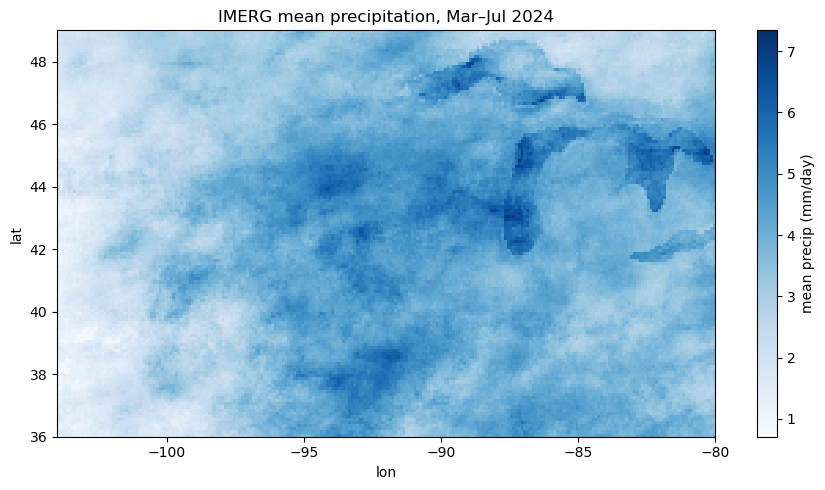

In [8]:
# map of season-mean precip -- should show a smooth west-dry / east-wet gradient, no stripes or speckle
import matplotlib.pyplot as plt
m = 24 * v.groupby(["grid_lat", "grid_lon"])["h_precip_mm"].mean().unstack()
plt.figure(figsize=(9, 5))
plt.pcolormesh(m.columns, m.index, m.values, cmap="Blues", shading="nearest")
plt.colorbar(label="mean precip (mm/day)")
plt.title(f"IMERG mean precipitation, Mar–Jul {YEAR}")
plt.xlabel("lon"); plt.ylabel("lat"); plt.tight_layout(); plt.show()